# 01. Bulk Download and Initial Data Profiling

This notebook:

1. Validates the BTS monthly ZIP URL pattern on a single test month.
2. Downloads, extracts and concatenates all twelve months of 2024.
3. Profiles the raw columns (the 109 fields BTS publishes) and narrows them to the 37 the analysis needs.
4. Saves two Parquet checkpoints (raw and narrowed) for the next notebooks.

**Scope.** Extraction and profiling only. The staging schema, the cleaning for the database and the load happen in Notebook 02.

**Prerequisites.** Internet access to `transtats.bts.gov` and several GB of free RAM. The full download took between 16 and 26 minutes in my runs, depending on how fast BTS was serving the files.

**Data source.** BTS Reporting Carrier On-Time Performance, published monthly by the U.S. Department of Transportation's Bureau of Transportation Statistics. It is distributed as pre-generated monthly ZIP files with a predictable URL and has no query API, so each month has to be downloaded whole and filtered locally.

I started this project with a different source: the freight-trip logistics times (RNDC) published by Colombia's Ministerio de Transporte on datos.gov.co, resource `tfrd-amb4`. After building its extraction and staging steps I confirmed that the resource only held January 2021 and had never been updated, so I replaced it with BTS.

# 1. Environment setup

Only extraction and profiling libraries are loaded here. The database stack comes in Notebook 02. `zipfile` and `io` let me read each ZIP from memory without writing intermediate files, and `tqdm` shows progress during the long download loop. I set a browser-like `User-Agent` because some TranStats endpoints reject the default `requests` header.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import gc
import io
import logging
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
from tqdm import tqdm

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

# Monthly ZIP pattern from the BTS TranStats PREZIP archive
BASE_URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

FIGURES_DIR = os.path.join("..", "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

# 2. Download and inspect one month

Before looping over a whole year I tested a single request and checked three things:

1. That the URL returns a real ZIP and not an HTML error page with a 200 status, a common failure with government download servers.
2. The file names inside the ZIP, since BTS doesn't document whether they stay stable.
3. The real columns and dtypes, to compare against the data dictionary.

January 2024 is the test month because it's recent and fully closed.

In [2]:
test_year = 2024
test_month = 1

url = BASE_URL_TEMPLATE.format(year=test_year, month=test_month)
logger.info(f"Requesting: {url}")

response = requests.get(url, headers=HEADERS, timeout=60)
response.raise_for_status()
logger.info(f"Status: {response.status_code} | Content-Type: {response.headers.get('Content-Type')} | Size: {len(response.content) / 1e6:.2f} MB")

# Inspect the ZIP contents before extracting
zip_file = zipfile.ZipFile(io.BytesIO(response.content))
print("Files inside ZIP:")
for name in zip_file.namelist():
    print(" -", name)

2026-10-06 10:36:18,191 - INFO - Requesting: https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2024_1.zip
2026-10-06 10:37:21,728 - INFO - Status: 200 | Content-Type: application/x-zip-compressed | Size: 27.57 MB


Files inside ZIP:
 - On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2024_1.csv
 - readme.html


The URL pattern works: status 200, `application/x-zip-compressed`, 27.57 MB. The ZIP holds the data CSV and a `readme.html`.

One detail matters for the loop. The CSV name uses parentheses (`(1987_present)`) where the URL uses underscores, so the file name can't be built from the URL. The loop has to pick whichever file inside the ZIP ends in `.csv`.

The request also took about a minute (63 seconds) for 27 MB. Twelve months will make a long cell, so the loop needs a generous timeout, visible progress and a retry per month, so that one slow request doesn't kill the whole batch.

# 3. Multi-month extraction loop

The loop covers January to December 2024 and follows from what Section 2 showed. The CSV is selected dynamically inside each ZIP, the timeout is 120 seconds and each month gets up to two attempts. Failed months are collected in a list, so I can see exactly what to re-run.

Each month is read from memory, appended to a list and concatenated once at the end, which is cheaper than concatenating inside the loop.

In [3]:
years_to_extract = [2024]
months_to_extract = list(range(1, 13))  # January to December

monthly_dataframes = []
failed_months = []
MAX_RETRIES = 2

for year in years_to_extract:
    for month in tqdm(months_to_extract, desc=f"Downloading {year}"):
        url = BASE_URL_TEMPLATE.format(year=year, month=month)
        success = False

        for attempt in range(1, MAX_RETRIES + 1):
            try:
                response = requests.get(url, headers=HEADERS, timeout=120)
                response.raise_for_status()

                zip_file = zipfile.ZipFile(io.BytesIO(response.content))
                csv_name = next(
                    name for name in zip_file.namelist()
                    if name.lower().endswith(".csv")
                )

                with zip_file.open(csv_name) as csv_file:
                    df_month = pd.read_csv(csv_file, low_memory=False)

                df_month["source_year"] = year
                df_month["source_month"] = month
                monthly_dataframes.append(df_month)

                logger.info(f"{year}-{month:02d}: OK ({len(df_month):,} rows)")
                success = True
                break

            except Exception as e:
                logger.warning(f"{year}-{month:02d}: attempt {attempt} failed — {e}")

        if not success:
            failed_months.append((year, month))
            logger.error(f"{year}-{month:02d}: FAILED after {MAX_RETRIES} attempts")

print(f"\nSuccessfully downloaded: {len(monthly_dataframes)} / {len(months_to_extract)} months")
print(f"Failed months: {failed_months}")


Successfully downloaded: 12 / 12 months
Failed months: []


In [4]:
df_raw = pd.concat(monthly_dataframes, ignore_index=True)
print(f"Total rows: {len(df_raw):,}")
print(f"Total columns: {df_raw.shape[1]}")
df_raw.head()

Total rows: 7,079,061
Total columns: 112


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,...,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109,source_year,source_month
0,2024,1,1,8,1,2024-01-08,9E,20363,9E,N485PX,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1
1,2024,1,1,9,2,2024-01-09,9E,20363,9E,N912XJ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1
2,2024,1,1,10,3,2024-01-10,9E,20363,9E,N918XJ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1
3,2024,1,1,11,4,2024-01-11,9E,20363,9E,N490PX,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1
4,2024,1,1,12,5,2024-01-12,9E,20363,9E,N915XJ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1


All 12 months downloaded on the first attempt: **7,079,061 rows**, about 8.5 times the single month the RNDC resource had. The loop took about 16 minutes on this run (26 on an earlier one).

Two things to carry into profiling:

1. **There are 112 columns**: the 109 fields BTS publishes, an empty `Unnamed: 109` column (each CSV line ends with a comma, so pandas reads one more column) and the two `source_` columns I added in the loop. That's far more than the ~29-column sample I looked at during initial research. Most of them are diversion-leg details and internal identifiers.
2. **`Year` and `Month` already exist in the source**, so the `source_year` and `source_month` columns I added in the loop are redundant. They are left out in Section 4.2.

## 3.1 Save raw checkpoint

The kernel crashed twice during my first pass at profiling (Section 4.2 explains why), and each crash meant downloading the year again. The source files don't change, so I save `df_raw` to Parquet here and resume from it when needed. Parquet is also smaller than CSV and keeps the dtypes.

In [5]:
os.makedirs("checkpoints", exist_ok=True)
df_raw.to_parquet("checkpoints/df_raw_2024_bts.parquet", index=False)
print("Checkpoint saved.")

Checkpoint saved.


# 4. Initial schema and data profiling

With 112 columns (109 of them from BTS), the first step is an inventory of every column (dtype, non-null count, % missing). Only then do I decide which fields the analysis needs: delay times, delay causes, routes and carriers.

## 4.1 Full column inventory

In [6]:
profile = pd.DataFrame({
    "dtype": df_raw.dtypes,
    "non_null_count": df_raw.notna().sum(),
    "pct_missing": (df_raw.isna().mean() * 100).round(2)
}).sort_values("pct_missing", ascending=False)

pd.set_option("display.max_rows", 120)
profile

,dtype,non_null_count,pct_missing
Div4WheelsOn,float64,0,100.00
Div4TotalGTime,float64,0,100.00
Div4LongestGTime,float64,0,100.00
Div4WheelsOff,float64,0,100.00
Div4TailNum,float64,0,100.00
Div5Airport,float64,0,100.00
Div5AirportID,float64,0,100.00
Div5AirportSeqID,float64,0,100.00
Div5WheelsOn,float64,0,100.00
Div5TotalGTime,float64,0,100.00


Most of the missingness is structural:

- The `Div1` to `Div5` groups (diversion legs) are 99.7–100% null. Diversions are rare, and very few diverted flights have a second or later diversion.
- `CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay` and `LateAircraftDelay` are 79.52% null by design. BTS only fills them when a flight arrives 15 or more minutes late.
- `DepDelay`, `ArrDelay`, `TaxiOut`, `TaxiIn` and similar fields (about 1.3–1.6% null) are empty mostly for cancelled flights, which never produced those events. Not all of them, though: there are 96,315 cancelled flights but only 92,659 missing `DepTime` values, so about 3,700 cancelled flights still record a departure, probably cancelled after leaving the gate. `ArrDelay` is null for exactly the cancelled plus the diverted flights (96,315 + 17,499 = 113,814), since diverted flights depart but never arrive at their destination.

None of this calls for imputation. I kept 37 columns covering flight identity, scheduled and actual times, delays, delay causes, cancellation and route. Diversion-leg details, BTS internal IDs and duplicated identifiers were dropped (for example, `Reporting_Airline` stays and `DOT_ID_Reporting_Airline` goes).

## 4.2 Column selection

This is where the two crashes came from. Holding the 112-column `df_raw` and a narrowed copy in memory at the same time, both with default 64-bit dtypes, was too much for the machine. The fix was to downcast numeric columns right after selecting them and free `df_raw` immediately.

In [7]:
columns_to_keep = [
    "Year", "Month", "DayofMonth", "DayOfWeek", "FlightDate", "Quarter",
    "Reporting_Airline", "Tail_Number", "Flight_Number_Reporting_Airline",
    "Origin", "OriginCityName", "OriginState",
    "Dest", "DestCityName", "DestState",
    "CRSDepTime", "DepTime", "DepDelay", "DepDel15",
    "CRSArrTime", "ArrTime", "ArrDelay", "ArrDel15",
    "Cancelled", "CancellationCode", "Diverted",
    "CRSElapsedTime", "ActualElapsedTime", "AirTime",
    "TaxiOut", "TaxiIn", "Distance",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]

df = df_raw[columns_to_keep].copy()

for col in df.select_dtypes(include="float64").columns:
    df[col] = pd.to_numeric(df[col], downcast="float")
for col in df.select_dtypes(include="int64").columns:
    df[col] = pd.to_numeric(df[col], downcast="integer")

del df_raw
gc.collect()

print(f"Shape after column selection: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Shape after column selection: (7079061, 37)
Memory usage: 4370.2 MB


## 4.3 Date coverage and missingness recap

The loop requested exactly twelve months, so coverage is guaranteed by construction. What I want to confirm is that no month was duplicated or misaligned during the concat, and to see the row count per month.

In [8]:
print("Rows per month:")
print(df.groupby(["Year", "Month"]).size())

print("\nMissingness on the narrowed column set:")
narrow_profile = pd.DataFrame({
    "dtype": df.dtypes,
    "pct_missing": (df.isna().mean() * 100).round(2)
}).sort_values("pct_missing", ascending=False)
narrow_profile

Rows per month:
Year  Month
2024  1        547271
      2        519221
      3        591767
      4        582185
      5        609743
      6        611132
      7        634613
      8        619025
      9        582622
      10       615497
      11       575404
      12       590581
dtype: int64

Missingness on the narrowed column set:


,dtype,pct_missing
CancellationCode,object,98.64
SecurityDelay,float32,79.52
CarrierDelay,float32,79.52
LateAircraftDelay,float32,79.52
NASDelay,float32,79.52
WeatherDelay,float32,79.52
ActualElapsedTime,float32,1.61
ArrDelay,float32,1.61
ArrDel15,float32,1.61
AirTime,float32,1.61


All twelve months are present, from 519,221 rows (February) to 634,613 (July). Higher summer volume is the expected seasonal pattern, and there are no gaps or spikes that would point to a merge error. Missingness on the 37 columns matches what Section 4.1 showed.

## 4.4 Flight volume by carrier

A quick visual check of `Reporting_Airline`. It should hold a small set of real carrier codes, and I wanted a first look at how concentrated the volume is, since carrier comparisons are central to Notebook 03.

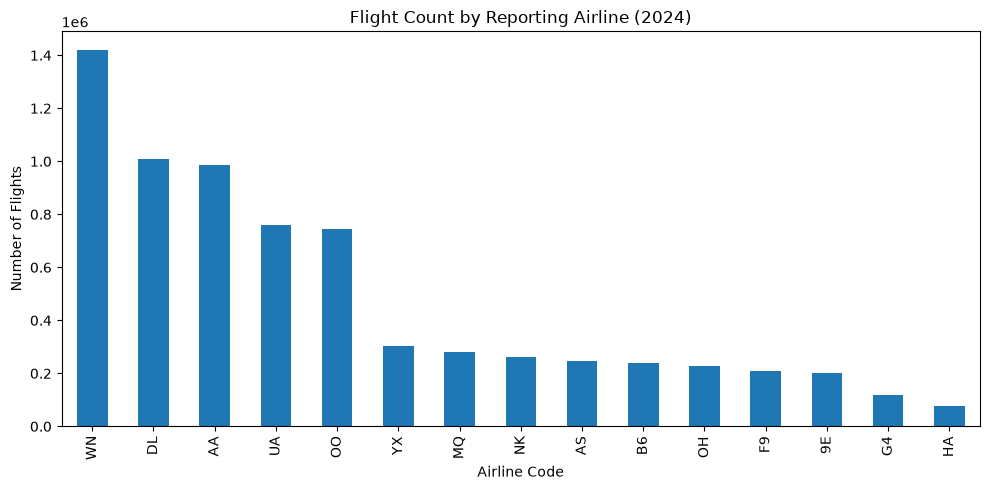

In [9]:
plt.figure(figsize=(10, 5))
df["Reporting_Airline"].value_counts().sort_values(ascending=False).plot(kind="bar")
plt.title("Flight Count by Reporting Airline (2024)")
plt.xlabel("Airline Code")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_flights_by_carrier.png"), dpi=150)
plt.show()

**WN (Southwest)** leads with about 1.4M flights, followed by **DL (Delta)** and **AA (American)** at around 1M each. After the top five (WN, DL, AA, UA, OO) there's a clear drop, then a long tail of regional and smaller carriers with fewer than 300K flights each.

The biggest carriers will dominate any unweighted aggregate, so carrier comparisons in Notebook 03 use averages and rates instead of raw counts.

## 4.5 Save narrowed checkpoint

`df_raw_2024_bts.parquet` stays as the archival copy of the full extraction. This second, smaller file with the 37 selected columns is what Notebook 02 loads.

In [10]:
df.to_parquet("checkpoints/df_narrowed_2024_bts.parquet", index=False)
print(f"Narrowed checkpoint saved: {df.shape}")

Narrowed checkpoint saved: (7079061, 37)


# 5. Conclusions

- All twelve months of 2024 downloaded through the PREZIP pattern with no failures: **7,079,061 flight records**.
- The 109 BTS fields were narrowed to **37**. Diversion-leg details, internal IDs and duplicated identifiers were dropped.
- Missingness in the kept columns is structural. Delay-cause fields are empty when a flight wasn't 15+ minutes late, time and taxi fields are empty for nearly all cancelled flights, and arrival fields also for diverted ones.
- Volume is heavily concentrated in WN, DL and AA, which shapes how carriers get compared later.
- Downcasting and freeing `df_raw` early fixed the memory crashes, and the two Parquet checkpoints let the next notebooks skip the download.

Notebook 02 takes the narrowed checkpoint into PostgreSQL.